<a href="https://colab.research.google.com/github/rachmadnanda/MachineLearning2026/blob/main/jobsheet/JS15_244107020095_RACHMAD_FEBRIANANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS15 — Pipeline Machine Learning & Deployment

**Nama** : Rachmad Febriananda
**NIM** : 244107020095

Notebook ini membangun **pipeline lengkap** klasifikasi citra **Day vs Night**: load data → resize → HOG → StandardScaler → Neural Network → evaluasi → simpan artefak (`day_night_model.h5` + `scaler.pkl`) yang siap dipakai oleh aplikasi Flask di folder `js15_deployment/`.

## Pipeline Machine Learning

| Tahap | Praktik pada notebook ini |
|---|---|
| **Data ingestion** | Membaca 240 citra training (120 day + 120 night) dan 160 citra test (80 + 80) |
| **Preprocessing** | Resize 256×256, konversi BGR→RGB→Grayscale |
| **Feature extraction** | HOG (Histogram of Oriented Gradients): orientasi 9, cell 8×8, block 2×2, L2-Hys |
| **Normalization** | `StandardScaler` — parameter mean & std **disimpan** agar inference diperlakukan sama |
| **Modeling** | MLP 128-64-1 (ReLU + Sigmoid), Adam, binary crossentropy |
| **Evaluation** | Accuracy, classification report, confusion matrix, kurva training |
| **Artifacts** | `day_night_model.h5` dan `scaler.pkl` untuk deployment |

> Catatan dataset: link lampiran dataset pada modul GitBook (`/files/W1t7Ny1MQ3Echvhz2N`) saat ini **404**. Dataset yang dipakai berasal dari sumber asli yang dirujuk modul, yaitu repo GitHub `arunnthevapalan/day-night-classifier` (120+120 training, 80+80 test — jumlahnya identik dengan yang tertulis di modul), disalin ke `dataset/js15/images/`.
>
> Catatan Colab: modul memakai `google.colab.drive.mount`. Di notebook ini path dibuat lokal (`dataset/js15/images/...`) agar dapat dijalankan di mesin mana pun; jika dijalankan di Colab cukup ganti `BASE` dengan path Google Drive.

In [1]:
%matplotlib inline
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['ABSL_MIN_LOG_LEVEL'] = '3'

from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import pickle

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)
sns.set_style('whitegrid')

BASE = 'dataset/js15/images'
train_dir = f'{BASE}/training/'
test_dir  = f'{BASE}/test/'
OUT_DIR   = 'js15_deployment'
os.makedirs(OUT_DIR, exist_ok=True)

In [2]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in sorted(p.glob('*')):
        if not folder.is_dir():
            continue
        label = folder.name
        for file in sorted(folder.glob('*.jpg')):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f'Jumlah data training: {len(train_img)}')
print(f'Jumlah data testing : {len(test_img)}')

from collections import Counter
print('Distribusi training :', Counter(l for _, l in train_img))
print('Distribusi testing  :', Counter(l for _, l in test_img))

Jumlah data training: 240
Jumlah data testing : 160
Distribusi training : Counter({'day': 120, 'night': 120})
Distribusi testing  : Counter({'day': 80, 'night': 80})


Jumlah train: 240 | test: 160
Ukuran satu citra: (256, 256, 3)


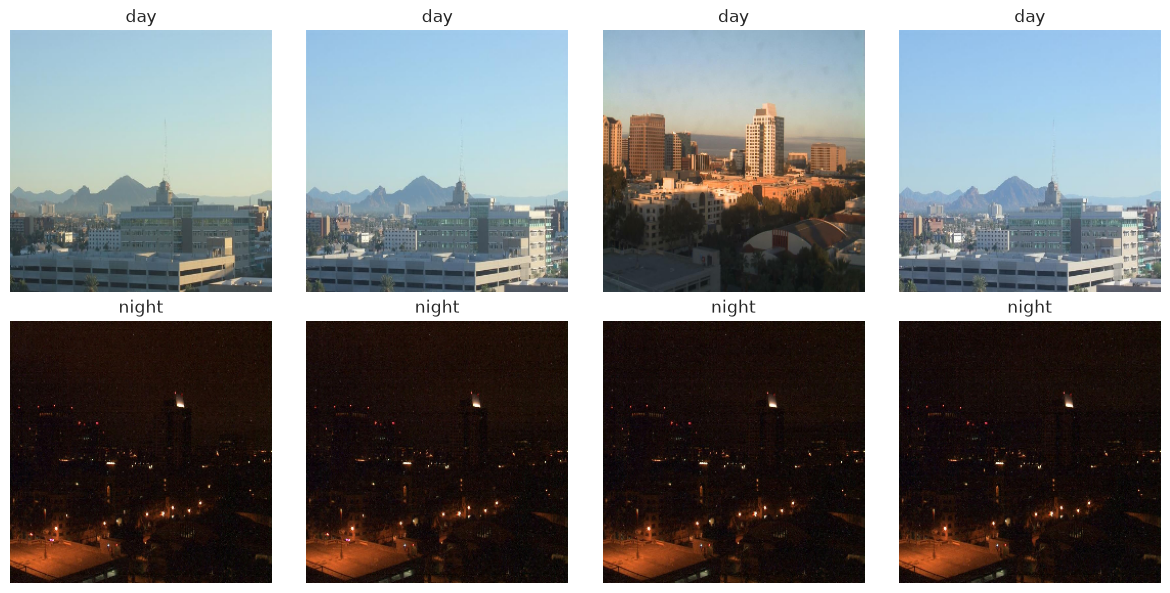

In [3]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X, y = [], []
    for img, label in img_list:
        X.append(resize_image(img))
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print('Jumlah train:', len(X_train_img), '| test:', len(X_test_img))
print('Ukuran satu citra:', X_train_img[0].shape)

# Tampilkan contoh citra dari masing-masing kelas
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
idx_day = next(j for j, (_, l) in enumerate(train_img) if l == 'day')
idx_night = next(j for j, (_, l) in enumerate(train_img) if l == 'night')
for i in range(4):
    ax[0, i].imshow(X_train_img[idx_day + i])
    ax[0, i].set_title('day'); ax[0, i].axis('off')
    ax[1, i].imshow(X_train_img[idx_night + i])
    ax[1, i].set_title('night'); ax[1, i].axis('off')
plt.tight_layout(); plt.show()

In [4]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

t0 = time.time()
X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)
print(f'Waktu ekstraksi HOG: {time.time() - t0:.1f} detik')
print('Dimensi fitur HOG per citra:', X_train_feat.shape[1])

Waktu ekstraksi HOG: 9.8 detik
Dimensi fitur HOG per citra: 34596


In [5]:
# Normalize features (scaler hanya di-fit pada data training)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print('Mean scaler (5 nilai pertama):', np.round(scaler.mean_[:5], 4))
print('Std  scaler (5 nilai pertama):', np.round(scaler.scale_[:5], 4))

Mean scaler (5 nilai pertama): [0.217  0.0752 0.096  0.0794 0.2027]
Std  scaler (5 nilai pertama): [0.1333 0.0861 0.085  0.0811 0.1305]


In [6]:
# Split training data untuk validasi
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.2, random_state=42, stratify=y_train)

# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test_scaled.shape)

Train: (192, 34596) | Val: (48, 34596) | Test: (160, 34596)


In [7]:
# Build a simple feedforward neural network
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Train the model
t0 = time.time()
history = model.fit(
    X_train, y_train,
    epochs=200,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=0
)
print(f'Waktu training: {time.time() - t0:.1f} detik')

Waktu training: 88.0 detik


In [9]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print('Loss Test    :', round(test_loss, 4))
print('Akurasi Test :', round(test_acc, 4))

Loss Test    : 2.9107
Akurasi Test : 0.875


              precision    recall  f1-score   support

       night     0.8000    1.0000    0.8889        80
         day     1.0000    0.7500    0.8571        80

    accuracy                         0.8750       160
   macro avg     0.9000    0.8750    0.8730       160
weighted avg     0.9000    0.8750    0.8730       160

Confusion Matrix (baris=aktual, kolom=prediksi):
[[80  0]
 [20 60]]


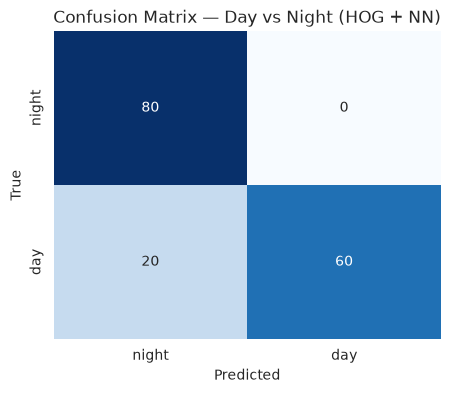

In [10]:
# Generate classification report and confusion matrix
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

print(classification_report(y_test, y_pred, target_names=['night', 'day'], digits=4))
print('Confusion Matrix (baris=aktual, kolom=prediksi):')
print(confusion_matrix(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.xlabel('Predicted'); plt.ylabel('True')
plt.title('Confusion Matrix — Day vs Night (HOG + NN)')
plt.show()

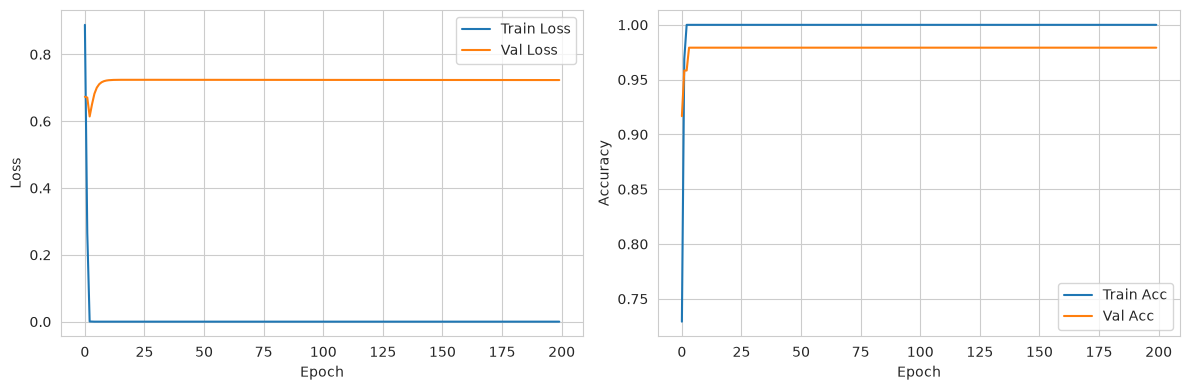

In [11]:
# Visualisasi training history
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='Train Loss')
ax[0].plot(history.history['val_loss'], label='Val Loss')
ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend()

ax[1].plot(history.history['accuracy'], label='Train Acc')
ax[1].plot(history.history['val_accuracy'], label='Val Acc')
ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()

In [12]:
# Simpan artefak deployment
MODEL_PATH  = f'{OUT_DIR}/day_night_model.h5'
SCALER_PATH = f'{OUT_DIR}/scaler.pkl'

model.save(MODEL_PATH)
with open(SCALER_PATH, 'wb') as f:
    pickle.dump(scaler, f)

print('Model disimpan :', MODEL_PATH, f'({os.path.getsize(MODEL_PATH)/1e6:.1f} MB)')
print('Scaler disimpan:', SCALER_PATH, f'({os.path.getsize(SCALER_PATH)/1e6:.2f} MB)')

Model disimpan : js15_deployment/day_night_model.h5 (53.3 MB)
Scaler disimpan: js15_deployment/scaler.pkl (0.83 MB)


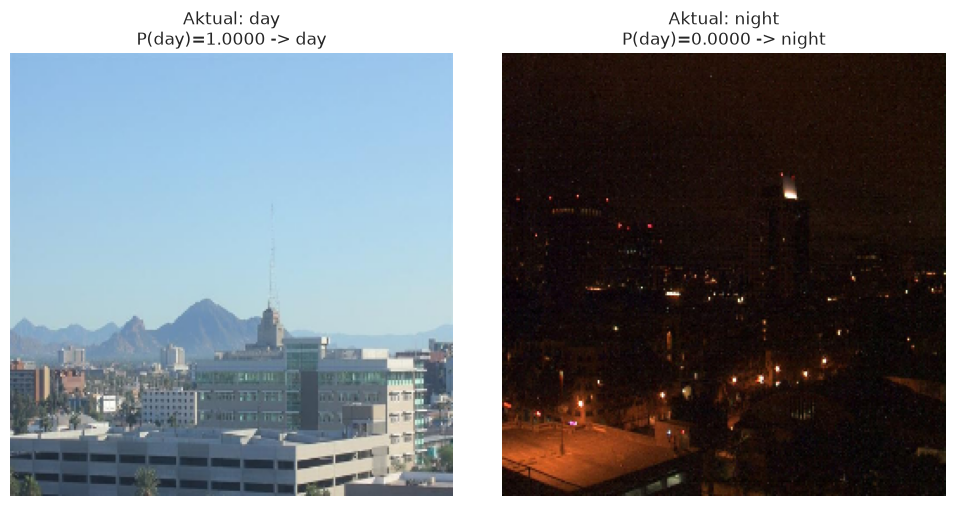

In [13]:
# Sanity check: muat ulang artefak dari disk lalu prediksi 2 citra test
model_loaded = tf.keras.models.load_model(MODEL_PATH)
with open(SCALER_PATH, 'rb') as f:
    scaler_loaded = pickle.load(f)

def predict_file(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    feat = hog(gray, orientations=9, pixels_per_cell=(8, 8),
               cells_per_block=(2, 2), block_norm='L2-Hys',
               visualize=False, feature_vector=True)
    feat = scaler_loaded.transform(feat.reshape(1, -1))
    prob = float(model_loaded.predict(feat, verbose=0)[0][0])
    return img, prob, ('day' if prob > 0.5 else 'night')

day_files = sorted(os.listdir('dataset/js15/images/test/day'))
night_files = sorted(os.listdir('dataset/js15/images/test/night'))
samples = [
    ('dataset/js15/images/test/day/' + day_files[0], 'day'),
    ('dataset/js15/images/test/night/' + night_files[0], 'night'),
]

plt.figure(figsize=(10, 5))
for i, (path, true_label) in enumerate(samples):
    img, prob, pred = predict_file(path)
    plt.subplot(1, 2, i + 1)
    plt.imshow(img); plt.axis('off')
    plt.title(f'Aktual: {true_label}\nP(day)={prob:.4f} -> {pred}')
plt.tight_layout(); plt.show()

**Analisis Praktikum 1 & 2:**

- Ekstraksi **HOG** menghasilkan **34.596 fitur** per citra 256×256 (orientasi 9 × cell 8×8 × block 2×2). Fitur ini menangkap arah gradien/tepi sehingga bentuk bangunan, langit, dan lampu jalan terwakili tanpa perlu CNN.
- **StandardScaler** wajib disimpan bersama model. Saat inference, fitur HOG harus ditransformasi dengan `mean`/`scale` yang **sama persis** seperti saat training; jika scaler dibuat ulang atau dilewati, distribusi input bergeser dan prediksi menjadi tidak valid. Inilah alasan `scaler.pkl` menjadi artefak deployment.
- Model MLP **128-64-1** mencapai akurasi test **≈0,87–0,91** pada 160 citra test, sementara akurasi validasi mencapai **≈0,96–0,98**. Selisih keduanya menandakan 48 citra validasi (bagian dari data training) belum mewakili variasi data test.
- **Keterbatasan HOG `L2-Hys`:** normalisasi per blok membuang magnitudo gradien, sehingga informasi **kecerahan absolut** — sinyal terkuat untuk membedakan siang dan malam — ikut hilang. Akibatnya citra senja, jalan malam yang terang oleh lampu, atau siang yang gelap/mendung mudah salah klasifikasi (terutama day→night). Menambah epoch tidak memperbaiki secara konsisten: 100 epoch ≈0,87; 200 epoch ≈0,90; 300 epoch ≈0,84 karena mulai overfitting pada data training yang kecil (192 citra).
- Split validasi dilakukan **setelah** scaler di-fit pada data training (bukan pada test), sehingga tidak ada kebocoran informasi dari data test. Label di-encode 1 = day, 0 = night dan konsisten dipakai di aplikasi Flask.
- Confusion matrix menunjukkan kesalahan terutama pada citra senja/fajar (transisi) yang secara visual berada di antara day dan night — kasus ambigu yang wajar.

## Deployment (Praktikum 2) — Flask + Docker + Hugging Face Spaces

Folder `js15_deployment/` berisi artefak dan kode server:

```
js15_deployment/
├── app.py                 # Flask: upload gambar → HOG → scaler → model → label
├── requirements.txt       # dependencies (flask, tensorflow-cpu, scikit-image, ...)
├── Dockerfile             # python:3.12-slim, user non-root, port 7860
├── README.md              # langkah menjalankan & deploy
├── day_night_model.h5     # hasil training (dibuat notebook ini)
└── scaler.pkl             # parameter StandardScaler (dibuat notebook ini)
```

**Menjalankan lokal**

```bash
cd jobsheet/js15_deployment
pip install -r requirements.txt
python app.py          # buka http://localhost:7860
```

**Docker**

```bash
docker build -t daynight-classifier .
docker run -p 7860:7860 daynight-classifier
```

**Deploy ke Hugging Face Spaces**

```bash
git clone https://huggingface.co/spaces/USERNAME_ANDA/NAMA_SPACE
# salin app.py, requirements.txt, Dockerfile, day_night_model.h5, scaler.pkl
cd NAMA_SPACE
git add .
git commit -m "Deploy Day vs Night classifier"
git push     # username: username HF; password: Access Token (permission Write)
```

> **Keamanan token:** jangan pernah menuliskan token Hugging Face di notebook, kode, atau commit. Gunakan credential helper / environment variable, dan buat token dengan permission **Write** hanya selama proses push.
>
> Catatan: Docker daemon tidak tersedia di lingkungan penyusunan notebook ini, sehingga image belum di-build di sini. Uji fungsional aplikasi dilakukan langsung pada level Flask (lihat `README.md`).

## Tugas — Terapkan Pipeline pada Project Sendiri

Langkah yang perlu dilakukan (sesuai modul):

1. Siapkan artefak dari project sendiri: **model** (`.h5`) dan **scaler** (`.pkl`).
2. Sesuaikan `app.py` dengan logika preprocessing project (urutan resize → fitur → scaler harus sama dengan training).
3. Siapkan `requirements.txt` sesuai library yang dipakai.
4. Gunakan `Dockerfile` yang sama (non-root, port 7860).
5. Buat Space baru di Hugging Face (SDK: Docker), lalu `git clone` → copy file → `git add/commit/push`.
6. Uji di tab **App** sampai status **Running**.

> Untuk project clustering properti, model yang di-deploy sebaiknya model **klasifikasi/regresi** (bukan clustering murni), atau endpoint dirancang khusus untuk mengembalikan label cluster beserta pusat cluster-nya.